In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import norm, poisson, binom, lognorm, pareto, boxcox, probplot, kstest, chisquare, shapiro
from scipy.special import inv_boxcox

sns.set_style("whitegrid")
ALPHA = 0.05
np.random.seed(42)

In [2]:
# 1. LOAD DATA

df = pd.read_csv('spread_locator_dataset.csv', parse_dates=['transaction_date'])
print('Shape:', df.shape)
print(df.dtypes)

amounts = df['transaction_amount'].values
log_amounts = np.log(amounts)

Shape: (220, 7)
transaction_id                   str
customer_id                      str
transaction_amount           float64
transaction_date      datetime64[us]
transaction_count              int64
region                           str
transaction_status               str
dtype: object


In [3]:
# 2. DESCRIPTIVES

desc = df[['transaction_amount','transaction_count']].describe().T
desc['skew'] = df[['transaction_amount','transaction_count']].skew()
desc['kurtosis'] = df[['transaction_amount','transaction_count']].kurtosis()
print('\nDescriptives:\n', desc.round(3))

print('\nStatus counts:\n', df['transaction_status'].value_counts())
print('\nRegion counts:\n', df['region'].value_counts())
print('\nCount distribution:\n',
      df['transaction_count'].value_counts().sort_index())


Descriptives:
                     count      mean       std     min       25%       50%  \
transaction_amount  220.0  3365.192  1985.705  804.42  2124.205  3077.715   
transaction_count   220.0     2.855     1.797    0.00     1.750     3.000   

                         75%       max   skew  kurtosis  
transaction_amount  3950.737  20462.84  3.756    25.946  
transaction_count      4.000      9.00  0.592     0.089  

Status counts:
 transaction_status
Fail       122
Success     98
Name: count, dtype: int64

Region counts:
 region
West     66
South    59
East     50
North    45
Name: count, dtype: int64

Count distribution:
 transaction_count
0    15
1    40
2    48
3    47
4    27
5    25
6    12
7     3
8     2
9     1
Name: count, dtype: int64


## 1.1 Bernoulli distribution – transaction occurrence

In [4]:
success = (df['transaction_status'] == 'Success').astype(int)
p_hat = success.mean(); n = len(success)
se = np.sqrt(p_hat*(1-p_hat)/n)
ci = norm.ppf([0.025, 0.975], p_hat, se)
print(f'\n[Bernoulli] p_hat={p_hat:.4f}, 95% CI=({ci[0]:.4f},{ci[1]:.4f})')


[Bernoulli] p_hat=0.4455, 95% CI=(0.3798,0.5111)


## 1.2 Binomial distribution – weekly transaction count

In [5]:
n_binom = 10
p_binom = df['transaction_count'].mean() / n_binom
print(f'\n[Binomial] n={n_binom}, p_hat={p_binom:.4f}, '
      f'mean={n_binom*p_binom:.3f}, var={n_binom*p_binom*(1-p_binom):.3f}')
print(f'Observed var = {df["transaction_count"].var(ddof=1):.3f}')


[Binomial] n=10, p_hat=0.2855, mean=2.855, var=2.040
Observed var = 3.230


## 2. Poisson distribution – number of transactions per day

In [6]:
daily = df.groupby('transaction_date').size()
lam_hat = daily.mean()
print(f'\n[Poisson] days={len(daily)}, lambda_hat={lam_hat:.3f}, '
      f'obs var={daily.var(ddof=1):.3f}, dispersion={daily.var(ddof=1)/lam_hat:.2f}')


[Poisson] days=31, lambda_hat=7.097, obs var=5.290, dispersion=0.75


## 3.1 LOG-NORMAL

In [7]:
mu_ln = log_amounts.mean()
sigma_ln = log_amounts.std(ddof=0)
implied_mean = np.exp(mu_ln + sigma_ln**2/2)
implied_median = np.exp(mu_ln)
implied_sd = np.sqrt((np.exp(sigma_ln**2)-1)*np.exp(2*mu_ln+sigma_ln**2))
print(f'\n[LogNormal] mu={mu_ln:.4f}, sigma={sigma_ln:.4f}')
print(f'  implied mean={implied_mean:.2f}, median={implied_median:.2f}, sd={implied_sd:.2f}')

# KS test on log scale
ks_stat, ks_p = kstest(log_amounts, lambda x: norm.cdf(x, loc=mu_ln, scale=sigma_ln))
print(f'  KS on log scale: D={ks_stat:.4f}, p={ks_p:.4f}')


[LogNormal] mu=8.0007, sigma=0.4749
  implied mean=3339.28, median=2983.16, sd=1679.66
  KS on log scale: D=0.0378, p=0.8999


## 3.2 POWER LAW (tail)

In [8]:
x_min = np.quantile(amounts, 0.80)
tail = amounts[amounts >= x_min]
alpha_hat = len(tail) / np.sum(np.log(tail / x_min))
print(f'\n[PowerLaw] x_min={x_min:.2f}, tail_n={len(tail)}, alpha_hat={alpha_hat:.3f}')

ll_ln = np.sum(lognorm.logpdf(tail, sigma_ln, scale=np.exp(mu_ln)))
ll_pl = np.sum(pareto.logpdf(tail, alpha_hat, scale=x_min))
print(f'  LogLik LogNormal={ll_ln:.2f}, LogLik PowerLaw={ll_pl:.2f}')


[PowerLaw] x_min=4360.46, tail_n=44, alpha_hat=3.555
  LogLik LogNormal=-440.35, LogLik PowerLaw=-369.30


## 4. Q-Q PLOTS

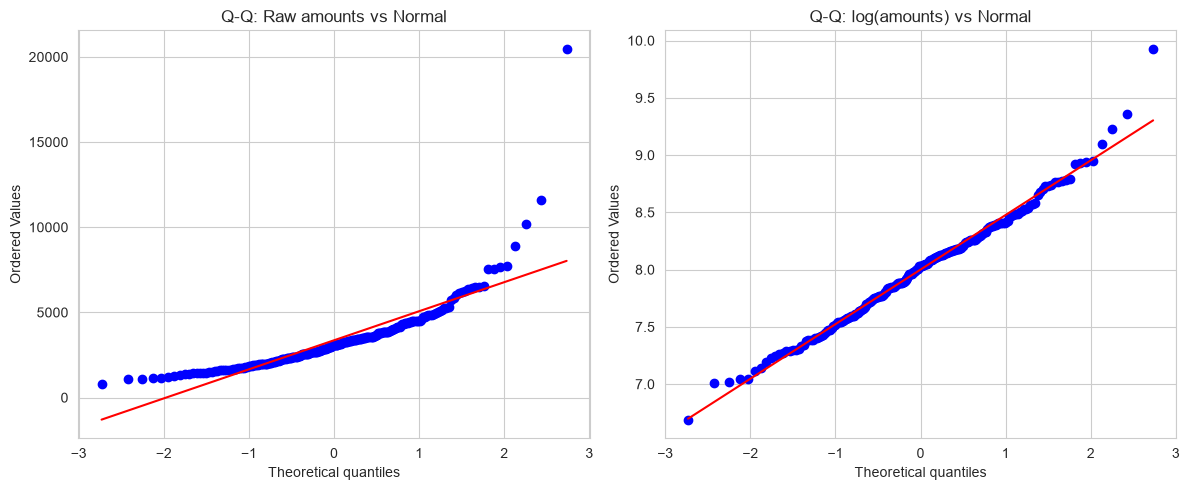


Shapiro raw: ShapiroResult(statistic=np.float64(0.7360905672029521), pvalue=np.float64(1.9104196066327837e-18))
Shapiro log: ShapiroResult(statistic=np.float64(0.989420720699164), pvalue=np.float64(0.10614734754375788))


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
probplot(amounts, dist='norm', plot=axes[0])
axes[0].set_title('Q-Q: Raw amounts vs Normal')
probplot(log_amounts, dist='norm', plot=axes[1])
axes[1].set_title('Q-Q: log(amounts) vs Normal')
plt.tight_layout()
plt.savefig('charts/qq_plots.png', dpi=150)
plt.show()

print('\nShapiro raw:', shapiro(amounts))
print('Shapiro log:', shapiro(log_amounts))

## 5. BOX-COX

Selected Box-Cox lambda: -0.1808
Original skewness: 3.7301
Transformed skewness: -0.0106


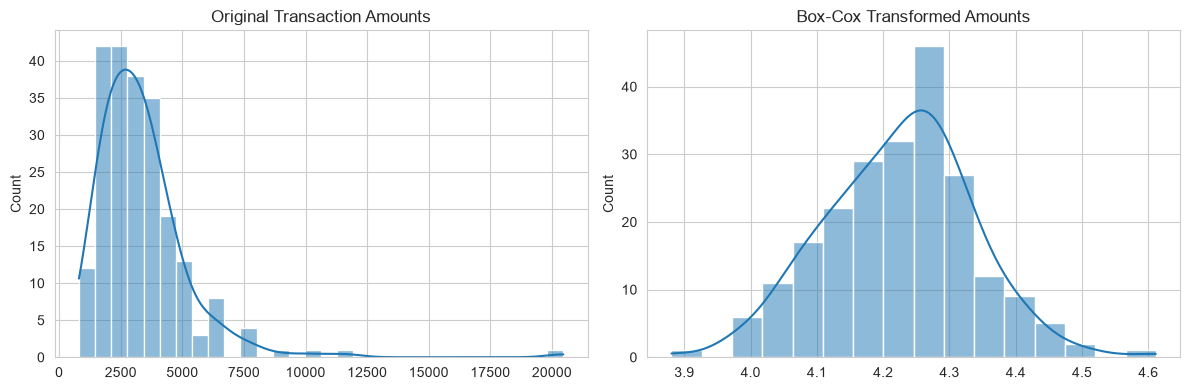

Interpretation: Compare the two histograms and skewness values. A transformed distribution closer to symmetry suggests that Box-Cox reduced skewness.


In [10]:
if len(amounts) >= 2 and (amounts > 0).all():
    transformed_amounts, lambda_value = stats.boxcox(amounts)
    print("Selected Box-Cox lambda:", round(lambda_value, 4))
    print("Original skewness:", round(stats.skew(amounts), 4))
    print("Transformed skewness:", round(stats.skew(transformed_amounts), 4))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(amounts, kde=True, ax=axes[0])
    axes[0].set_title("Original Transaction Amounts")
    sns.histplot(transformed_amounts, kde=True, ax=axes[1])
    axes[1].set_title("Box-Cox Transformed Amounts")
    plt.tight_layout()
    plt.savefig('charts/Box-Cox.png', dpi=150)
    plt.show()

    print("Interpretation: Compare the two histograms and skewness values. A transformed distribution closer to symmetry suggests that Box-Cox reduced skewness.")
else:
    print("Box-Cox requires at least two strictly positive transaction amounts.")

## 6. Z-SCORE / P(X>5000)

In [11]:
mu, sd = amounts.mean(), amounts.std(ddof=1)
z = (5000 - mu) / sd
p_norm = 1 - norm.cdf(z)
p_ln = 1 - lognorm.cdf(5000, sigma_ln, scale=np.exp(mu_ln))
p_emp = (amounts > 5000).mean()
print(f'\n[Z-score] mean={mu:.2f}, sd={sd:.2f}, z(5000)={z:.4f}')
print(f'  P(X>5000): Normal={p_norm:.4f}, LogNormal={p_ln:.4f}, Empirical={p_emp:.4f}')


[Z-score] mean=3365.19, sd=1985.71, z(5000)=0.8233
  P(X>5000): Normal=0.2052, LogNormal=0.1384, Empirical=0.1136


## 7. PDF & CDF 

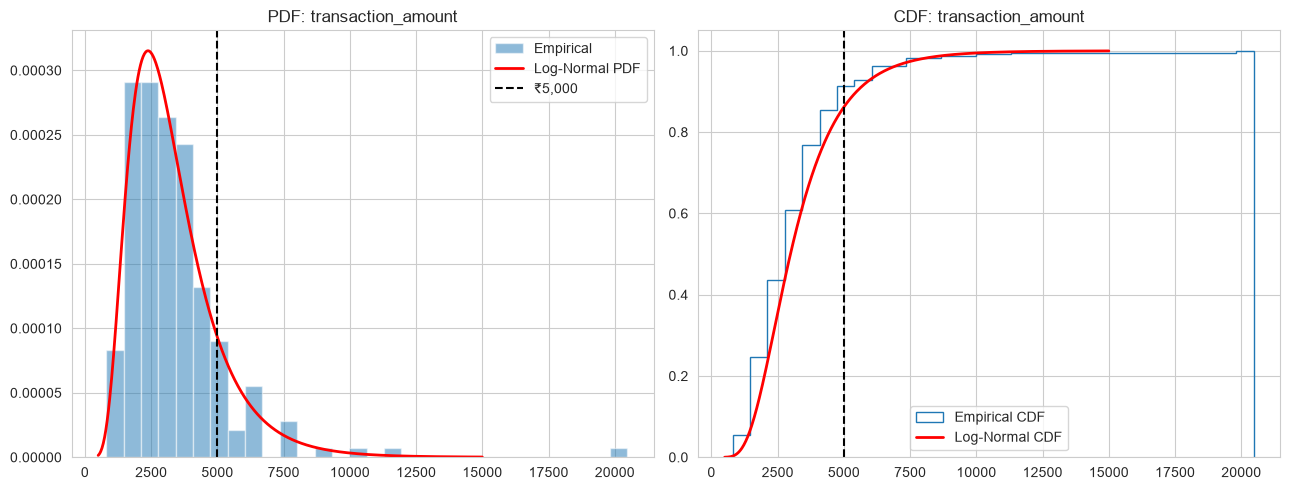

In [12]:
x_grid = np.linspace(500, 15000, 600)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(amounts, bins=30, density=True, alpha=0.5, label='Empirical')
axes[0].plot(x_grid, lognorm.pdf(x_grid, sigma_ln, scale=np.exp(mu_ln)),
             'r-', lw=2, label='Log-Normal PDF')
axes[0].axvline(5000, color='k', ls='--', label='₹5,000')
axes[0].set_title('PDF: transaction_amount'); axes[0].legend()

axes[1].hist(amounts, bins=30, density=True, cumulative=True,
             histtype='step', label='Empirical CDF')
axes[1].plot(x_grid, lognorm.cdf(x_grid, sigma_ln, scale=np.exp(mu_ln)),
             'r-', lw=2, label='Log-Normal CDF')
axes[1].axvline(5000, color='k', ls='--')
axes[1].set_title('CDF: transaction_amount'); axes[1].legend()

plt.tight_layout()
plt.savefig('charts/pdf_cdf_lognormal.png', dpi=150)
plt.show()

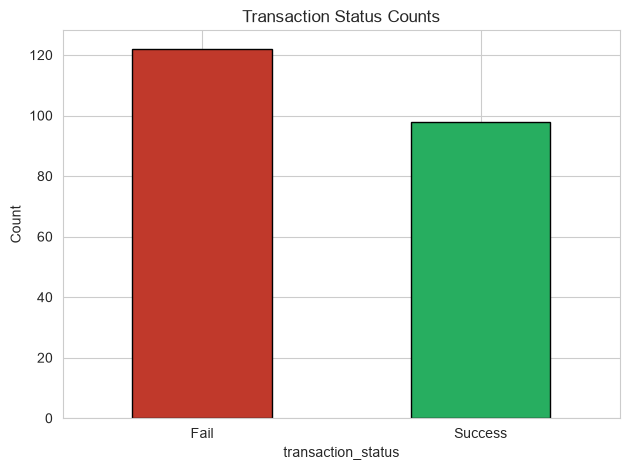

In [13]:
# a. Status bar
df['transaction_status'].value_counts().plot(kind='bar',
    color=['#c0392b','#27ae60'], edgecolor='k')
plt.title('Transaction Status Counts')
plt.ylabel('Count'); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig('charts/status_bar.png', dpi=150); plt.show()

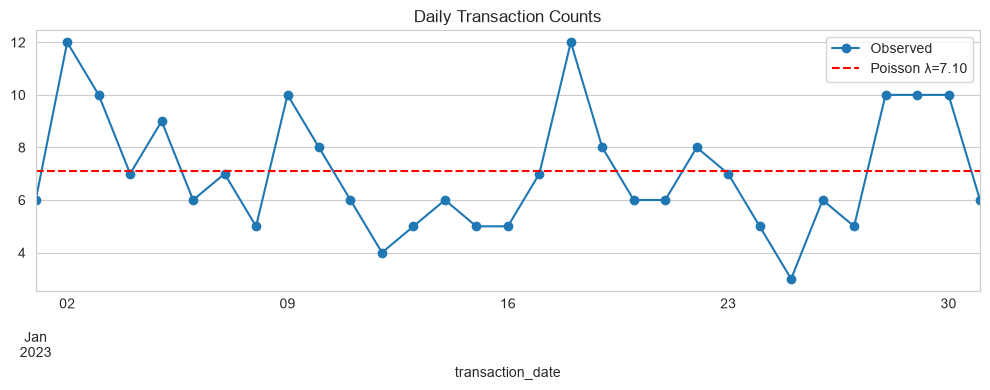

In [14]:
# b. Daily transaction counts + Poisson fit
fig, ax = plt.subplots(figsize=(10,4))
daily.plot(marker='o', ax=ax, label='Observed')
ax.axhline(lam_hat, color='r', ls='--', label=f'Poisson λ={lam_hat:.2f}')
ax.set_title('Daily Transaction Counts'); ax.legend()
plt.tight_layout(); plt.savefig('charts/daily_counts.png', dpi=150); plt.show()

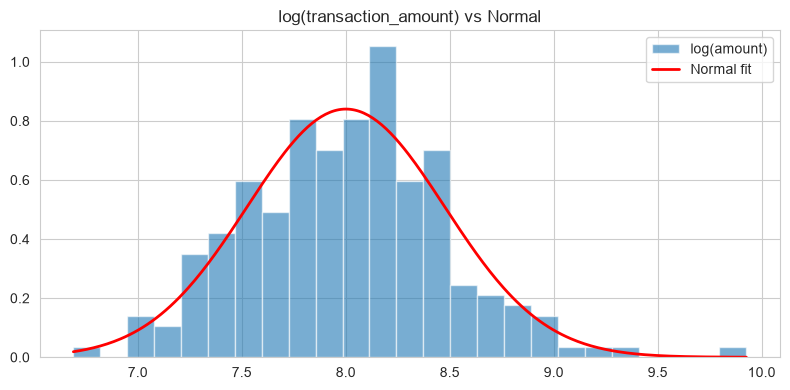

In [15]:
# c. Histogram of log amounts
fig, ax = plt.subplots(figsize=(8,4))
ax.hist(log_amounts, bins=25, density=True, alpha=0.6, label='log(amount)')
xg = np.linspace(log_amounts.min(), log_amounts.max(), 300)
ax.plot(xg, norm.pdf(xg, mu_ln, sigma_ln), 'r-', lw=2, label='Normal fit')
ax.set_title('log(transaction_amount) vs Normal'); ax.legend()
plt.tight_layout(); plt.savefig('charts/log_amounts_hist.png', dpi=150); plt.show()

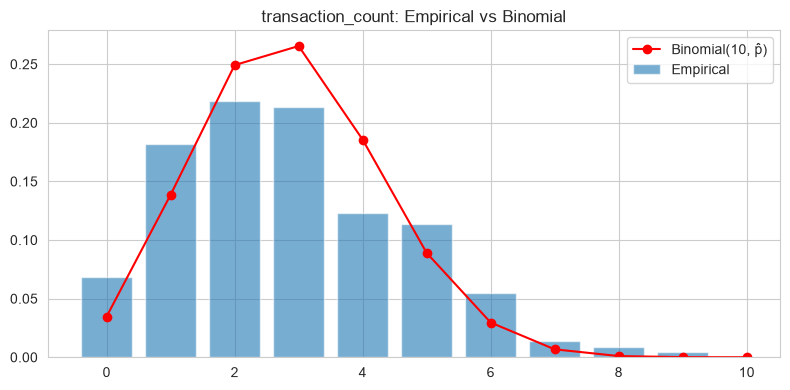

In [16]:
# d. transaction_count distribution + Binomial overlay
fig, ax = plt.subplots(figsize=(8,4))
vals = df['transaction_count'].value_counts().sort_index()
ax.bar(vals.index, vals.values/len(df), alpha=0.6, label='Empirical')
ks = np.arange(0, n_binom+1)
ax.plot(ks, binom.pmf(ks, n_binom, p_binom), 'ro-', label='Binomial(10, p̂)')
ax.set_title('transaction_count: Empirical vs Binomial'); ax.legend()
plt.tight_layout(); plt.savefig('charts/count_binomial.png', dpi=150); plt.show()

## 8. SUMMARY TABLE

In [17]:
summary = pd.DataFrame([
    {'Model': 'Bernoulli', 'Parameter': f'p={p_hat:.4f}', 'Target': 'transaction_status'},
    {'Model': 'Binomial(10)', 'Parameter': f'p={p_binom:.4f}', 'Target': 'transaction_count'},
    {'Model': 'Poisson', 'Parameter': f'λ={lam_hat:.3f}', 'Target': 'daily transaction count'},
    {'Model': 'Log-Normal', 'Parameter': f'μ={mu_ln:.3f}, σ={sigma_ln:.3f}',
     'Target': 'transaction_amount (BEST FIT)'},
    {'Model': 'Power Law', 'Parameter': f'α={alpha_hat:.3f}',
     'Target': 'upper tail of transaction_amount'},
])
print('\n=== FINAL SUMMARY ===')
print(summary.to_string(index=False))


=== FINAL SUMMARY ===
       Model        Parameter                           Target
   Bernoulli         p=0.4455               transaction_status
Binomial(10)         p=0.2855                transaction_count
     Poisson          λ=7.097          daily transaction count
  Log-Normal μ=8.001, σ=0.475    transaction_amount (BEST FIT)
   Power Law          α=3.555 upper tail of transaction_amount
